# Brooks-Corey Model (1964)
::):retirado de Vinicius Czarnobay

${k_{ro}} = {k_{ro\max }}{\left( {\dfrac{{{S_o} - {S_{or}}}}{{1 - {S_{or}} - {S_{wi}}}}} \right)^{{n_o}}} = {k_{ro\max }}{\left( {\dfrac{{1 - {S_w} - {S_{or}}}}{{1 - {S_{or}} - {S_{wi}}}}} \right)^{{n_o}}}$

$$ $$

${k_{rw}} = {k_{rw\max }}{\left( {\dfrac{{{S_w} - {S_{wi}}}}{{1 - {S_{or}} - {S_{wi}}}}} \right)^{{n_w}}}$

In [406]:
import numpy as np
import matplotlib.pyplot as plt


# Geração dos pontos a partir do Modelo

In [407]:
def curva_permeabilidade(k_romax = 0.5, Sor = 0.2, no = 3.,
                         k_rwmax = 0.4, Swi = 0.3, nw = 2.):
    
    Sw = np.linspace(0, 1, 211)
    num = 1 - Sw  - Sor
    den = 1 - Sor - Swi
    k_ro = k_romax * ( num / den ) ** no

    num2 = Sw  - Swi
    k_rw = k_rwmax * ( num2 / den ) ** nw

    antes = np.where( Sw <= Swi )[0]
    x0 = Sw[antes[-1]]
    y0o = k_ro[antes[-1]]
    y0w = k_rw[antes[-1]]

    depois = np.where( Sw >= 1-Sor )[0]
    xf = Sw[depois[0]]
    yfo = k_ro[depois[0]]
    yfw = k_rw[depois[0]]

    pontos = (x0, xf, y0o, y0w, yfo, yfw)

    k_ro[antes]  = k_ro[antes[-1]]
    k_rw[antes]  = k_rw[antes[-1]]
    k_ro[depois] = k_ro[depois[0]]
    k_rw[depois] = k_rw[depois[0]]

    return [Sw, k_ro, k_rw, pontos]
    

# Gráfico a partir dos pontos gerados

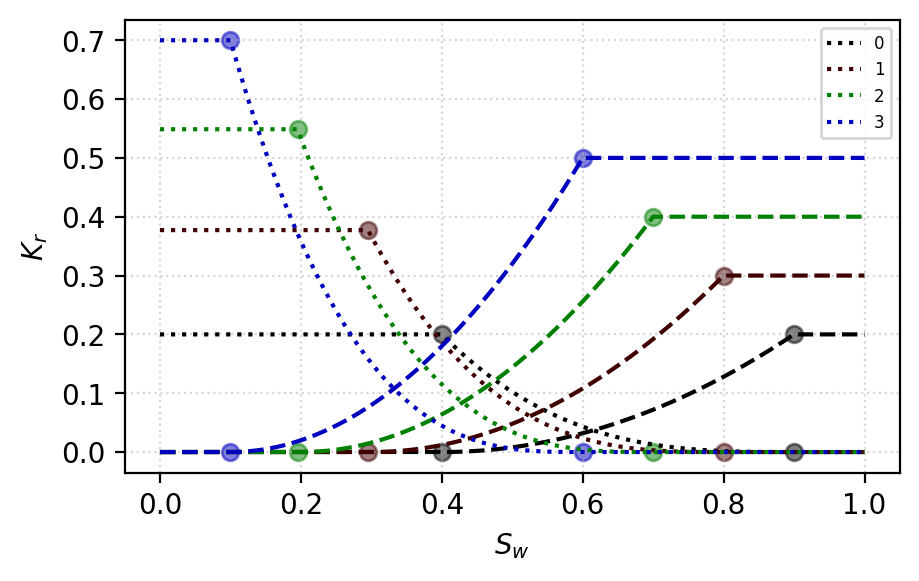

In [408]:
k_romax = np.linspace(0.2, 0.7, 4)
k_rwmax = np.linspace(0.2, 0.5, 4)
Sor     = np.linspace(0.1, 0.4, 4)
Swi     = np.linspace(0.4, 0.1, 4)
plt.figure(figsize=(5,3), dpi=200)
for ii in range(len(k_romax)):
    [Sw, k_ro, k_rw, pontos] = curva_permeabilidade(k_romax = k_romax[ii], 
                                            Sor = Sor[ii], 
                                            Swi = Swi[ii], 
                                            no = 3.,
                                            k_rwmax = k_rwmax[ii], nw = 2.)
    (x0, xf, y0o, y0w, yfo, yfw) = pontos
    if np.mod(ii, 2)==0:
        cor = (0, ii/len(k_romax), 0)
    elif np.mod(ii, 3)==0:
        cor = (0, 0, ii/len(k_romax))
    else:
        cor = (ii/len(k_romax), 0, 0)

    plt.plot(Sw, k_ro, label=str(ii), color=cor, ls=':' )
    plt.plot(Sw, k_rw,                color=cor, ls='--')
    plt.scatter(x0, y0o, color=cor, alpha=0.5)
    plt.scatter(xf, yfo, color=cor, alpha=0.5)
    plt.scatter(x0, y0w, color=cor, alpha=0.5)
    plt.scatter(xf, yfw, color=cor, alpha=0.5)
plt.legend(fontsize=6)
plt.grid(ls=":", alpha=0.5)
plt.xlabel("$S_w$")
plt.ylabel("$K_r$")
plt.show()

In [409]:

x0

0.1